In [22]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from langchain_core.messages import HumanMessage
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
load_dotenv()

# =========================================================
# 1. DEFINE STATE
# =========================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]


# =========================================================
# 2. CREATE LLM
# =========================================================

llm = init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq"
)


In [2]:
def chatbot(state: State):

    print("\n--- Inside chatbot node ---")

    print("Current state:")
    print(state)

    # Get messages from current state
    messages = state["messages"]
    print("msg",messages)
    # Send messages to LLM
    response = llm.invoke(messages)

    print("\nLLM Response:")
    print(response.content)

    # Return updated state
    return {
        "messages": [response]
    }


In [ ]:
graph_builder = StateGraph(State)

graph_builder.add_edge(
    START,
    "chatbot"
)

# Add node
graph_builder.add_node(
    "chatbot",
    chatbot
)


graph_builder.add_edge(
    "chatbot",
    END
)


# =========================================================
# 6. COMPILE GRAPH
# =========================================================

graph = graph_builder.compile()

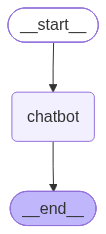

In [4]:
graph

In [5]:
response = graph.invoke(
    {
        "messages": [
            HumanMessage(content="What is AI?")
        ]
    }
)


# =========================================================
# 8. PRINT FINAL RESPONSE
# =========================================================

print("\n==============================")
print("FINAL RESPONSE")
print("==============================")

print(response["messages"][-1].content)


--- Inside chatbot node ---
Current state:
{'messages': [HumanMessage(content='What is AI?', additional_kwargs={}, response_metadata={}, id='ab6b9d6c-4383-4c78-b546-36e8b6e117bc')]}
msg [HumanMessage(content='What is AI?', additional_kwargs={}, response_metadata={}, id='ab6b9d6c-4383-4c78-b546-36e8b6e117bc')]

LLM Response:
**Artificial Intelligence (AI)** is a branch of computer science that focuses on creating systems capable of performing tasks that typically require human intelligence. These tasks include:

| Category | Examples | Typical Techniques |
|----------|----------|--------------------|
| **Perception** | Recognizing objects in images, understanding spoken language | Convolutional Neural Networks (CNNs), Recurrent Neural Networks (RNNs), Transformers |
| **Reasoning & Decision‑Making** | Planning routes, playing chess, diagnosing diseases | Search algorithms, rule‑based systems, Bayesian networks |
| **Learning** | Adjusting to new data, improving performance over time | 

In [ ]:
from langchain.chat_models import init_chat_model
from typing import TypedDict
from typing import Annotated

from langgraph.graph.message import add_messages
from langgraph.graph import START,END,StateGraph
from dotenv import load_dotenv
load_dotenv()

class State(TypedDict):
    messages: Annotated[list,add_messages] # we are using this to pass or invoke the message

    # # State does not automatically mean list. You wrote messages: list, so that field supports a list.


In [24]:
llm_invokes=init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq"
)

In [ ]:
def Chatbot(state: State):
    print("Lets Start")
    print(state["messages"]) 
    msg = state["messages"]
    res=llm_invokes.invoke(msg)
    print(res.content)
    return res

In [52]:
graph_builders=StateGraph(State)


graph_builders.add_edge(START,"chatbot") # START = where the graph starts. "chatbot" = the name of the node.
graph_builders.add_node("chatbot",Chatbot) # add_node(node_name, function) syntacs
graph_builders.add_edge("chatbot",END) # START can only be the source, and END can only be the destination.

graph = graph_builders.compile()

In [54]:
graph.invoke({
    "messages":[HumanMessage("What is India")]
})

Lets Start
[HumanMessage(content='What is India', additional_kwargs={}, response_metadata={}, id='86f4c8b9-243d-465b-958b-df3778eb717a')]
**India** is a country in South Asia and is the world's **second‑largest** democracy by population (over 1.4 billion people). It is bordered by the Indian Ocean to the south, the Arabian Sea to the west, the Bay of Bengal to the east, and shares land borders with Pakistan (west), China, Nepal, Bhutan, and Bangladesh (north and east).

---

### Key facts

| Category | Details |
|----------|---------|
| **Capital** | New Delhi (official), Mumbai (commercial hub) |
| **Official language** | Hindi (official), English (associate official) – plus 21 other scheduled languages |
| **Area** | ~3.29 million km² (≈ 1.27 million sq mi) |
| **Population** | ~1.4 billion (2024 estimate) |
| **Government** | Federal parliamentary democratic republic |
| **Currency** | Indian rupee (₹) |
| **Time zone** | Indian Standard Time (UTC+5:30) |
| **Climate** | Tropical to

{'messages': [HumanMessage(content='What is India', additional_kwargs={}, response_metadata={}, id='86f4c8b9-243d-465b-958b-df3778eb717a')]}